In [5]:
import pandas as pd

df = pd.read_csv("data/subway_congestion.csv", encoding="cp949")
df.head()

,구분,호선,역번호,역명,상하구분,5시30분,6시00분,6시30분,7시00분,7시30분,...,20시00분,20시30분,21시00분,21시30분,22시00분,22시30분,23시00분,23시30분,00시00분,00시30분
0,평일,1호선,150,서울역,상선,8.9,21.2,22.7,41.3,72.1,...,18.3,17.9,19.3,16.0,16.4,17.2,13.6,8.9,7.1,1.6
1,평일,1호선,150,서울역,하선,11.5,11.2,16.4,22.4,40.2,...,40.5,40.4,42.5,38.6,38.6,31.0,18.6,13.7,9.7,0.0
2,평일,1호선,151,시청,상선,7.3,15.8,18.2,30.6,54.8,...,21.8,22.1,22.3,21.1,20.7,20.0,17.8,10.2,7.5,1.6
3,평일,1호선,151,시청,하선,9.2,10.4,17.0,21.9,36.7,...,36.2,37.8,41.1,31.9,34.5,26.9,17.2,12.7,6.7,0.4
4,평일,1호선,152,종각,상선,6.8,14.6,11.4,20.0,31.9,...,28.2,28.8,30.3,27.7,27.4,26.4,24.4,12.8,8.4,1.5


In [7]:
# 시간대 컬럼 선택
time_cols = df.columns[5:]

# 각 행의 평균 혼잡도 계산
df["평균혼잡도"] = df[time_cols].mean(axis=1)

# 호선별 평균 혼잡도 계산
line_avg = df.groupby("호선")["평균혼잡도"].mean()

line_avg

호선
1호선    27.233846
2호선    32.877968
3호선    25.958371
4호선    31.203008
5호선    26.869458
6호선    23.836544
7호선    31.615140
8호선    29.650270
Name: 평균혼잡도, dtype: float64

In [8]:
# 평균 혼잡도가 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 소수점 둘째 자리까지 표시
line_rank.round(2)

호선
2호선    32.88
7호선    31.62
4호선    31.20
8호선    29.65
1호선    27.23
5호선    26.87
3호선    25.96
6호선    23.84
Name: 평균혼잡도, dtype: float64

In [9]:
# 가장 혼잡한 호선
print("가장 혼잡한 호선:", line_rank.idxmax())
print("평균 혼잡도:", round(line_rank.max(), 2), "%")

# 가장 한산한 호선
print("가장 한산한 호선:", line_rank.idxmin())
print("평균 혼잡도:", round(line_rank.min(), 2), "%")

가장 혼잡한 호선: 2호선
평균 혼잡도: 32.88 %
가장 한산한 호선: 6호선
평균 혼잡도: 23.84 %


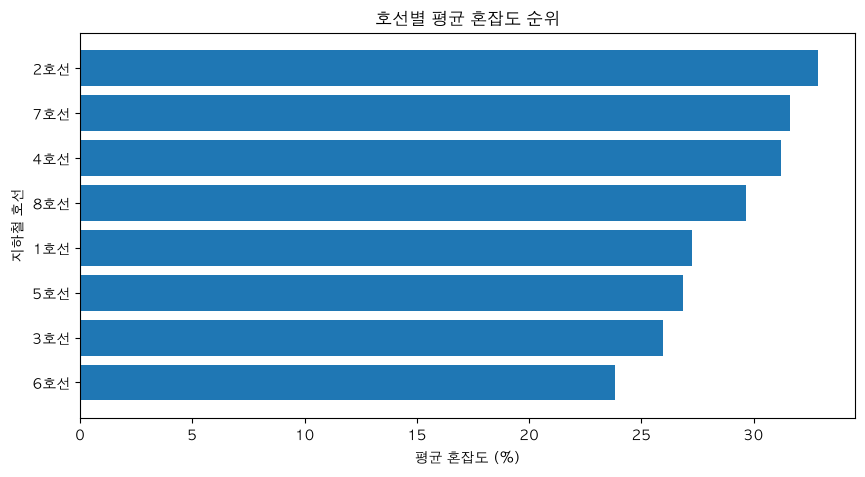

In [15]:
import matplotlib.pyplot as plt

# 맥북 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 평균 혼잡도 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 가로 막대그래프 생성
plt.figure(figsize=(10, 5))

plt.barh(line_rank.index, line_rank.values)

# 혼잡도가 높은 호선이 위쪽에 오도록 설정
plt.gca().invert_yaxis()

# 그래프 제목 및 축 이름
plt.title("호선별 평균 혼잡도 순위")
plt.xlabel("평균 혼잡도 (%)")
plt.ylabel("지하철 호선")

plt.show()